<a href="https://colab.research.google.com/github/kieshaaaa/aircraft-enginer-rul-prediction/blob/main/classical_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. first we load our CMAPP dataset. we first make use of dataset FD001

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv("/content/train_FD001.txt", sep=r"\s+", header=None, names=columns)
test = pd.read_csv("/content/test_FD001.txt", sep=r"\s+", header=None, names=columns)
test_rul = pd.read_csv("/content/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

train.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


2. Now we check the data structure

In [61]:
print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Test RUL shape:", test_rul.shape)
print("Training engines:", train["engine_id"].nunique())
print("Test engines:", test["engine_id"].nunique())
print("Missing training values:", train.isna().sum().sum())
print("Missing test values:", test.isna().sum().sum())

lifetimes = train.groupby("engine_id")["cycle"].max()
print("\nTraining engine lifetimes (cycles):")
print("Shortest:", lifetimes.min(), "| Longest:", lifetimes.max(), "| Average:", round(lifetimes.mean(), 1))

Training shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)
Training engines: 100
Test engines: 100
Missing training values: 0
Missing test values: 0

Training engine lifetimes (cycles):
Shortest: 128 | Longest: 362 | Average: 206.3


3. now we calculate the RUL from the training data

In [62]:
final_cycle = train.groupby("engine_id")["cycle"].transform("max")
train["RUL"] = final_cycle - train["cycle"]

print(train[["engine_id", "cycle", "RUL"]].head(10))

   engine_id  cycle  RUL
0          1      1  191
1          1      2  190
2          1      3  189
3          1      4  188
4          1      5  187
5          1      6  186
6          1      7  185
7          1      8  184
8          1      9  183
9          1     10  182


4. we cap RUL at 125

In [63]:
train["RUL_capped"] = train["RUL"].clip(upper=125)

print(train[["engine_id", "cycle", "RUL", "RUL_capped"]].head(10))
print("Max capped RUL:", train["RUL_capped"].max())

   engine_id  cycle  RUL  RUL_capped
0          1      1  191         125
1          1      2  190         125
2          1      3  189         125
3          1      4  188         125
4          1      5  187         125
5          1      6  186         125
6          1      7  185         125
7          1      8  184         125
8          1      9  183         125
9          1     10  182         125
Max capped RUL: 125


5. we plot sensor readings for one engine

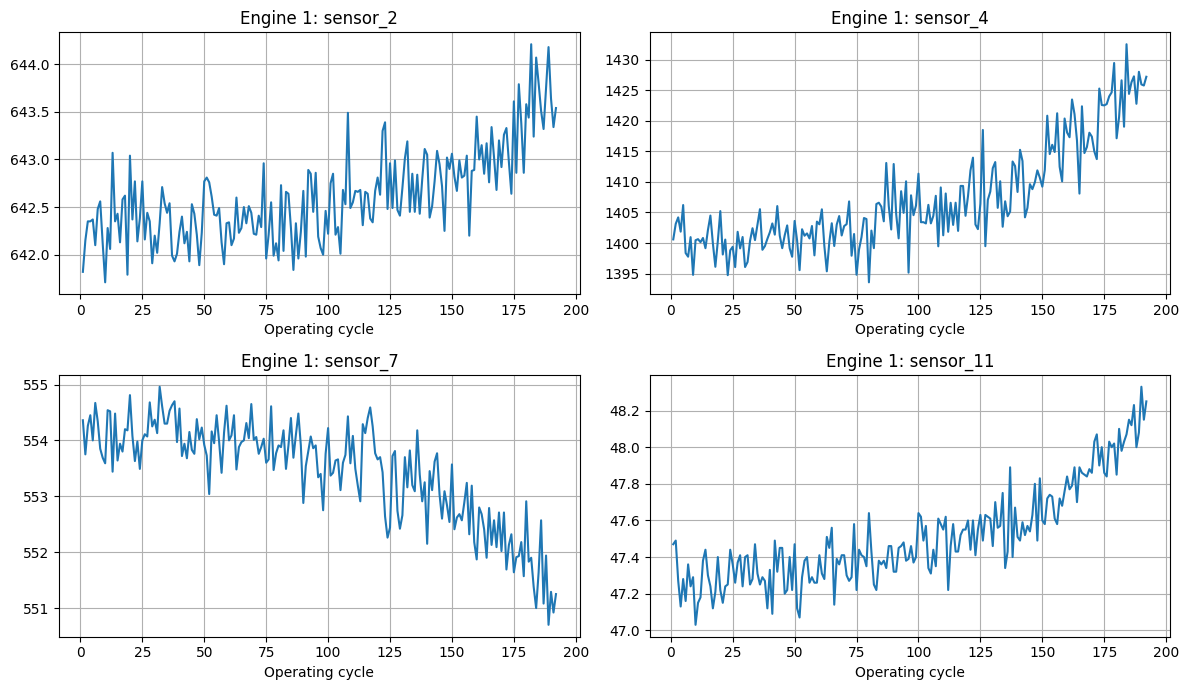

In [64]:
engine = train[train["engine_id"] == 1]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, sensor in zip(axes.flat, ["sensor_2", "sensor_4", "sensor_7", "sensor_11"]):
    ax.plot(engine["cycle"], engine[sensor])
    ax.set_title(f"Engine 1: {sensor}")
    ax.set_xlabel("Operating cycle")
    ax.grid(True)

plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

6. now  find and drop uninformative sensors

In [65]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

print("Standard deviation of each sensor:")
print(train[sensor_cols].std().sort_values())

drop_sensors = [c for c in sensor_cols if train[c].std() < 0.01]
features = [c for c in sensor_cols if c not in drop_sensors]

print("\nDropped:", drop_sensors)
print("Using", len(features), "sensors:", features)

Standard deviation of each sensor:
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

Dropped: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Using 14 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


7. split the training engine 80/20

In [66]:
rng = np.random.default_rng(42)
engines = train["engine_id"].unique()
val_engines = rng.choice(engines, size=20, replace=False)

tr = train[~train["engine_id"].isin(val_engines)]
val = train[train["engine_id"].isin(val_engines)]

print("Training engines:", tr["engine_id"].nunique(), "| rows:", len(tr))
print("Validation engines:", val["engine_id"].nunique(), "| rows:", len(val))
print("Overlap between the two:", set(tr["engine_id"]) & set(val["engine_id"]))

Training engines: 80 | rows: 16390
Validation engines: 20 | rows: 4241
Overlap between the two: set()


8. scaling the sensors,fitted on training engines only

In [67]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_tr = scaler.fit_transform(tr[features])
y_tr = tr["RUL_capped"].values

X_val = scaler.transform(val[features])
y_val = val["RUL_capped"].values

print("X_tr:", X_tr.shape, "| X_val:", X_val.shape)
print("Training min/max after scaling:", X_tr.min().round(2), X_tr.max().round(2))

X_tr: (16390, 14) | X_val: (4241, 14)
Training min/max after scaling: 0.0 1.0


9. Preparing the test set (last cycle of each engine)

In [68]:
test_last = test.groupby("engine_id").last().reset_index()
X_test = scaler.transform(test_last[features])
y_test = test_rul["RUL"].values

print("X_test:", X_test.shape, "| y_test:", y_test.shape)

X_test: (100, 14) | y_test: (100,)


10: Evaluation function

In [69]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

def evaluate(name, model):
    row = {"Model": name}
    for split, X, y in [("Val", X_val, y_val), ("Test", X_test, y_test)]:
        pred = np.clip(model.predict(X), 0, None)
        row[f"{split} MAE"] = round(mean_absolute_error(y, pred), 2)
        row[f"{split} RMSE"] = round(np.sqrt(mean_squared_error(y, pred)), 2)
    results.append(row)
    print(row)

11. naive baseline and linear regression

In [70]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

baseline = DummyRegressor(strategy="mean").fit(X_tr, y_tr)
evaluate("Naive baseline (mean RUL)", baseline)

lr = LinearRegression().fit(X_tr, y_tr)
evaluate("Linear Regression", lr)

{'Model': 'Naive baseline (mean RUL)', 'Val MAE': 37.05, 'Val RMSE': np.float64(41.59), 'Test MAE': 35.9, 'Test RMSE': np.float64(43.0)}
{'Model': 'Linear Regression', 'Val MAE': 17.19, 'Val RMSE': np.float64(21.05), 'Test MAE': 17.6, 'Test RMSE': np.float64(21.87)}


12. Random forest and sensor importance

{'Model': 'Random Forest', 'Val MAE': 13.06, 'Val RMSE': np.float64(17.65), 'Test MAE': 13.26, 'Test RMSE': np.float64(18.29)}


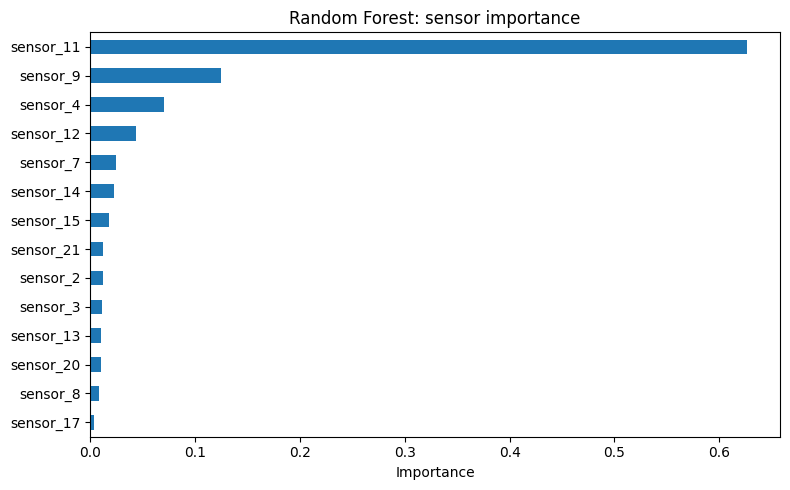

In [71]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr)
evaluate("Random Forest", rf)

importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", figsize=(8, 5), title="Random Forest: sensor importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

13. results table

In [72]:
pd.DataFrame(results)

,Model,Val MAE,Val RMSE,Test MAE,Test RMSE
0,Naive baseline (mean RUL),37.05,41.59,35.90,43.00
1,Linear Regression,17.19,21.05,17.60,21.87
2,Random Forest,13.06,17.65,13.26,18.29


14. adding the nasa score and re-scoring the models based on that


In [73]:
def nasa_score(y_true, y_pred):
    d = y_pred - y_true   # positive = late prediction (dangerous)
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

results = []

def evaluate(name, model):
    row = {"Model": name}
    for split, X, y in [("Val", X_val, y_val), ("Test", X_test, y_test)]:
        pred = np.clip(model.predict(X), 0, None)
        row[f"{split} MAE"] = round(mean_absolute_error(y, pred), 2)
        row[f"{split} RMSE"] = round(np.sqrt(mean_squared_error(y, pred)), 2)
    test_pred = np.clip(model.predict(X_test), 0, None)
    row["Test NASA score"] = round(nasa_score(y_test, test_pred), 1)
    results.append(row)
    print(row)

for name, model in [("Naive baseline (mean RUL)", baseline),
                    ("Linear Regression", lr),
                    ("Random Forest", rf)]:
    evaluate(name, model)

{'Model': 'Naive baseline (mean RUL)', 'Val MAE': 37.05, 'Val RMSE': np.float64(41.59), 'Test MAE': 35.9, 'Test RMSE': np.float64(43.0), 'Test NASA score': np.float64(32772.2)}
{'Model': 'Linear Regression', 'Val MAE': 17.19, 'Val RMSE': np.float64(21.05), 'Test MAE': 17.6, 'Test RMSE': np.float64(21.87), 'Test NASA score': np.float64(1303.7)}
{'Model': 'Random Forest', 'Val MAE': 13.06, 'Val RMSE': np.float64(17.65), 'Test MAE': 13.26, 'Test RMSE': np.float64(18.29), 'Test NASA score': np.float64(1173.7)}


15. XGBOOST

In [74]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb.fit(X_tr, y_tr)
evaluate("XGBoost", xgb)

{'Model': 'XGBoost', 'Val MAE': 13.19, 'Val RMSE': np.float64(17.98), 'Test MAE': 13.65, 'Test RMSE': np.float64(18.76), 'Test NASA score': np.float64(1164.7)}


16. update results table

In [59]:
pd.DataFrame(results)

,Model,Val MAE,Val RMSE,Test MAE,Test RMSE,Test NASA score
0,Naive baseline (mean RUL),37.05,41.59,35.90,43.00,32772.2
1,Linear Regression,17.19,21.05,17.60,21.87,1303.7
2,Random Forest,13.06,17.65,13.26,18.29,1173.7
3,XGBoost,13.19,17.98,13.65,18.76,1164.7
